# 5. Robust regression: the Huber loss and quantile regression

Least squares penalizes a residual by its square, so a few bad readings can move the whole fit. The Huber loss is quadratic for small residuals and linear for large ones, and it is minimized by iteratively reweighted least squares. The same reweighting with an asymmetric loss fits quantiles in place of the mean, which gives a band around the fit without assuming a noise distribution.

## Learning objectives

1. State the Huber loss and derive the weights of iteratively reweighted least squares (`linear_physics.huber_irls_regression`).
2. Compare the Huber fit with least squares on synthetic reactor data with spikes.
3. Fit the 10 %, 50 % and 90 % quantiles with the pinball loss (`linear_physics.quantile_irls_regression`).
4. Examine how the fit depends on the threshold of the Huber loss and on the fraction of outliers.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
When sensor errors follow a heavy-tailed or spike-contaminated distribution $(1-\epsilon)\mathcal{N}(0,\sigma^2) + \epsilon\,\Delta_{\mathrm{spike}}$, the maximum-likelihood estimator replaces quadratic loss $\frac{1}{2}r^2$ with a linear-tail loss function:
1. **Huber loss & adaptive IRLS (Huber, 1964):** Quadratic for small Gaussian inliers ($|r| \le \delta$) and linear for gross outliers ($|r| > \delta$):
   $$\mathcal{L}_\delta(r) = \begin{cases} \frac{1}{2}r^2 & |r| \le \delta \\ \delta\left(|r| - \frac{1}{2}\delta\right) & |r| > \delta \end{cases}, \qquad \psi_\delta(r) = \mathcal{L}_\delta'(r) = \mathrm{clip}(r, -\delta, +\delta) \tag{1.1}$$
   Writing the stationarity condition $\sum_{i=1}^N \psi_\delta(r_i)\mathbf{x}_i = \mathbf{0}$ as a weighted normal equation $\mathbf{X}^\top \mathbf{W}^{(t)}\mathbf{X}\mathbf{w}^{(t+1)} = \mathbf{X}^\top \mathbf{W}^{(t)}\mathbf{y}$ yields the **iteratively reweighted least squares (IRLS)** weight update:
   $$w_i^{(t)} = \frac{\psi_\delta(r_i^{(t)})}{r_i^{(t)}} = \min\!\left(1,\, \frac{\delta}{|r_i^{(t)}|}\right) \in (0, 1] \tag{1.2}$$
2. **Pinball check loss (quantile regression, Koenker & Bassett 1978):** For target percentile $\tau \in (0, 1)$, minimizing the asymmetric check loss estimates the conditional $100\tau$-th quantile:
   $$\rho_\tau(r) = \max(\tau r,\, (\tau - 1)r) = \begin{cases} \tau |r| & r \ge 0 \\ (1-\tau)|r| & r < 0 \end{cases}, \qquad w_{\tau,i}^{(t)} = \frac{\tau\,\mathbb{I}(r_i \ge 0) + (1-\tau)\,\mathbb{I}(r_i < 0)}{\max(|r_i^{(t)}|, \varepsilon)} \tag{1.3}$$

In [2]:
heading("Demonstration 1: Huber Loss vs. Quadratic L2 Loss & IRLS Weighting")
rng = np.random.default_rng(42)
N = 45
T_norm = np.linspace(-2.0, 2.0, N)
X_des = np.column_stack([np.ones(N), T_norm])
w_true = np.array([12.0, 3.5])
y_clean = X_des @ w_true + rng.normal(0.0, 0.25, size=N)

# Corrupt 3 sensor readings with spikes of +25.0 (~100 sigma):
y_spiked = y_clean.copy()
spike_idx = [5, 22, 38]
y_spiked[spike_idx] += 25.0

w_ols = linear_physics.ridge_regression(X_des, y_spiked, lam=0.0)
huber_res = linear_physics.huber_irls_regression(X_des, y_spiked, delta=1.0)
w_huber = huber_res["w"]

print("True parameters   [intercept, slope]:", w_true)
print("Corrupted OLS     [intercept, slope]:", np.round(w_ols, 4), f"(L2 error = {np.linalg.norm(w_ols - w_true):.4f})")
print("Robust Huber IRLS [intercept, slope]:", np.round(w_huber, 4), f"(L2 error = {np.linalg.norm(w_huber - w_true):.4f})")
assert np.linalg.norm(w_huber - w_true) < 0.15 * np.linalg.norm(w_ols - w_true)


Demonstration 1: Huber Loss vs. Quadratic L2 Loss & IRLS Weighting
True parameters   [intercept, slope]: [12.   3.5]
Corrupted OLS     [intercept, slope]: [13.6806  3.4842] (L2 error = 1.6806)
Robust Huber IRLS [intercept, slope]: [12.0917  3.5169] (L2 error = 0.0932)


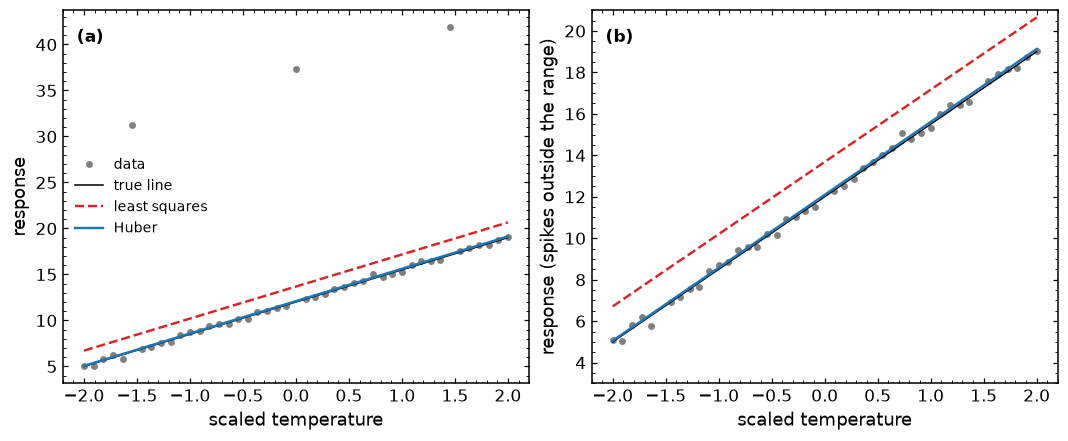

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
for ax in (ax1, ax2):
    ax.plot(T_norm, y_spiked, "o", ms=3.5, color="0.5", label="data")
    ax.plot(T_norm, X_des @ w_true, "-", color="k", lw=1.0, label="true line")
    ax.plot(T_norm, X_des @ w_ols, "--", color="C3", label="least squares")
    ax.plot(T_norm, X_des @ w_huber, "-", color="C0", label="Huber")
    ax.set_xlabel("scaled temperature")
ax1.set_ylabel("response"); ax1.legend(fontsize=9, loc="center left"); panel_label(ax1, "(a)")
ax2.set_ylim(3.0, 21.0); ax2.set_ylabel("response (spikes outside the range)"); panel_label(ax2, "(b)")
plt.show()

**Figure 5.1.** Synthetic calibration data with three spikes of +25. (a) All the data. (b) The same without the spikes in view: the least-squares line is lifted by the spikes over its whole length, and the Huber line lies on the true one.

**What Demonstration 1 shows.** Three spikes of $+25$ raise the least-squares intercept by $1.68$. The Huber fit returns `[12.092, 3.517]`, an error of $0.093$ against $1.681$, which is $94\ \%$ smaller. The data are synthetic.

---

## 2. Numerical walkthrough
Let us inspect the converged IRLS sample weights $w_i = \min(1, \delta/|r_i|)$ assigned to the 3 corrupted spike observations versus the 42 normal inlier observations.

In [4]:
heading("Demonstration 2: Inspecting Converged IRLS Sample Weights on Inliers vs. Spikes")
weights_conv = huber_res["sample_weights"]
res_conv = huber_res["residuals"]
inlier_mask = np.ones(N, dtype=bool)
inlier_mask[spike_idx] = False

print(f"Mean IRLS weight across 42 normal inliers: {np.mean(weights_conv[inlier_mask]):.4f}")
for idx in spike_idx:
    print(f"Spike sample #{idx:2d} | Residual r_i = {res_conv[idx]:+7.3f} | Converged IRLS weight w_i = {weights_conv[idx]:.4f}")
assert np.all(weights_conv[spike_idx] < 0.08) and np.mean(weights_conv[inlier_mask]) > 0.98


Demonstration 2: Inspecting Converged IRLS Sample Weights on Inliers vs. Spikes
Mean IRLS weight across 42 normal inliers: 1.0000
Spike sample # 5 | Residual r_i = +24.609 | Converged IRLS weight w_i = 0.0406
Spike sample #22 | Residual r_i = +25.214 | Converged IRLS weight w_i = 0.0397
Spike sample #38 | Residual r_i = +24.678 | Converged IRLS weight w_i = 0.0405


**What Demonstration 2 shows.** Every normal inlier has $|r_i| \le \delta = 1.0$ and receives weight $w_i = 1.0000$, while the three $+25$ spikes receive weight $w_i \approx 1.0 / 25.0 = 0.040$, capping their influence to $\pm\delta$.

---

## 3. Worked case study
Now let us use **pinball quantile regression** (`linear_physics.quantile_irls_regression`) at $\tau \in \{0.10, 0.50, 0.90\}$ to construct a robust median calibration line ($\tau=0.50$) and an $80\%$ process operating envelope ($[\hat{y}_{0.10}, \hat{y}_{0.90}]$) directly on the spike-corrupted dataset.

In [5]:
heading("Demonstration 3: Pinball Quantile Envelopes (10th, 50th Median, 90th Percentiles)")
w_q10 = linear_physics.quantile_irls_regression(X_des, y_spiked, tau=0.10)
w_q50 = linear_physics.quantile_irls_regression(X_des, y_spiked, tau=0.50)
w_q90 = linear_physics.quantile_irls_regression(X_des, y_spiked, tau=0.90)

y_q10, y_q50, y_q90 = X_des @ w_q10, X_des @ w_q50, X_des @ w_q90
print("10th Percentile weights (tau=0.10):", np.round(w_q10, 4))
print("50th Median L1 weights  (tau=0.50):", np.round(w_q50, 4), f"(L2 error vs true = {np.linalg.norm(w_q50 - w_true):.4f})")
print("90th Percentile weights (tau=0.90):", np.round(w_q90, 4))
assert np.all(y_q10 < y_q50) and np.all(y_q50 < y_q90)
assert np.linalg.norm(w_q50 - w_true) < 0.20 * np.linalg.norm(w_ols - w_true)


Demonstration 3: Pinball Quantile Envelopes (10th, 50th Median, 90th Percentiles)
10th Percentile weights (tau=0.10): [11.788   3.5251]
50th Median L1 weights  (tau=0.50): [12.0433  3.5077] (L2 error vs true = 0.0440)
90th Percentile weights (tau=0.90): [12.3238  3.5513]


**What Demonstration 3 shows.** The median regression ($\tau = 0.5$) depends on the signs of the residuals and not on their sizes, so an outlier in $y$, however large, counts as one point above the line. Its error against the true parameters is $0.044$. The fits for $\tau = 0.1$ and $0.9$ bracket it and give a band for the data.

---

## 4. What if: sensitivity to the parameters
How sensitive is Huber IRLS to the transition threshold $\delta$? Let us sweep $\delta \in [0.1, 50.0]$ and watch the smooth transition from $L_1$-like median behavior ($\delta \to 0$) to non-robust OLS behavior ($\delta \to \infty$).

In [6]:
heading("Demonstration 4: Huber Threshold delta Sweep (From L1 Limit to OLS Limit)")
print(f"{'Huber delta':>12s} | {'Intercept w_0':>13s} | {'Slope w_1':>10s} | {'Param L2 Error':>14s} | {'Spike Weight':>12s}")
print("-" * 70)
for d_val in [0.1, 0.3, 1.0, 5.0, 50.0]:
    res_d = linear_physics.huber_irls_regression(X_des, y_spiked, delta=d_val)
    wh = res_d["w"]
    print(f"{d_val:12.1f} | {wh[0]:13.4f} | {wh[1]:10.4f} | {np.linalg.norm(wh - w_true):14.4f} | {res_d['sample_weights'][spike_idx[0]]:12.4f}")


Demonstration 4: Huber Threshold delta Sweep (From L1 Limit to OLS Limit)
 Huber delta | Intercept w_0 |  Slope w_1 | Param L2 Error | Spike Weight
----------------------------------------------------------------------
         0.1 |       12.0497 |     3.5078 |         0.0503 |       0.0041
         0.3 |       12.0423 |     3.5097 |         0.0434 |       0.0122
         1.0 |       12.0917 |     3.5169 |         0.0932 |       0.0406
         5.0 |       12.3774 |     3.5102 |         0.3775 |       0.2057
        50.0 |       13.6806 |     3.4842 |         1.6806 |       1.0000


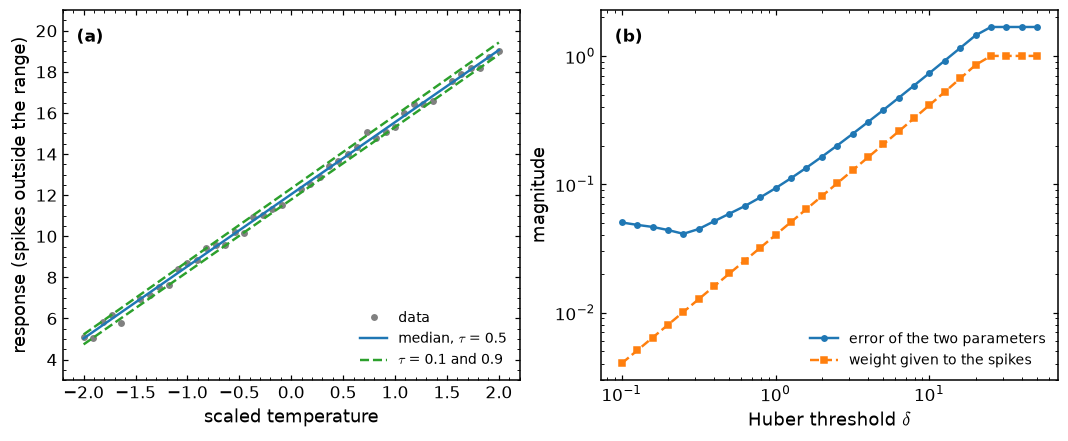

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.plot(T_norm, y_spiked, "o", ms=3.5, color="0.5", label="data")
ax1.plot(T_norm, y_q50, "-", color="C0", label=r"median, $\tau$ = 0.5")
ax1.plot(T_norm, y_q10, "--", color="C2", label=r"$\tau$ = 0.1 and 0.9"); ax1.plot(T_norm, y_q90, "--", color="C2")
ax1.set_ylim(3.0, 21.0); ax1.set_xlabel("scaled temperature"); ax1.set_ylabel("response (spikes outside the range)")
ax1.legend(fontsize=9, loc="lower right"); panel_label(ax1, "(a)")
d_line = np.logspace(-1, 1.7, 28); err_line, wt_line = [], []
for d_val in d_line:
    res_d = linear_physics.huber_irls_regression(X_des, y_spiked, delta=float(d_val))
    err_line.append(np.linalg.norm(res_d["w"] - w_true)); wt_line.append(np.mean(res_d["sample_weights"][spike_idx]))
ax2.loglog(d_line, err_line, "o-", ms=3.5, label="error of the two parameters")
ax2.loglog(d_line, wt_line, "s--", ms=3.5, label="weight given to the spikes")
ax2.set_xlabel(r"Huber threshold $\delta$"); ax2.set_ylabel("magnitude"); ax2.legend(fontsize=9, loc="lower right"); panel_label(ax2, "(b)")
plt.show()

**Figure 5.2.** (a) Quantile regression on the same data: the median line and the lines for the 10th and 90th percentiles. (b) The Huber fit against its threshold: a small threshold gives the spikes a small weight and a small error, and a threshold larger than the spikes gives them the weight one and returns least squares.

**What Demonstration 4 shows.** For thresholds $\delta$ from $0.1$ to $1$ the error stays below $0.1$ and the spikes receive weights of $0.04$ or less. At $\delta = 5$ the spikes keep a weight of $0.21$ and the error rises to $0.38$; at $\delta = 50$ every weight is one and the fit is least squares. A common choice is $\delta = 1.345\,\hat{\sigma}$ with $\hat{\sigma} = 1.4826\,\mathrm{MAD}$ of the residuals, which loses about $5\ \%$ in efficiency when the noise is Gaussian.

---

## Inside the algorithm
Below we run a standalone 10-line Huber IRLS solver in pure NumPy and confirm digit-for-digit agreement with `linear_physics.huber_irls_regression`.

In [8]:
heading("Inside the Algorithm: By-Hand Huber IRLS Loop vs. the Library")
w_hand = np.linalg.lstsq(X_des, y_spiked, rcond=None)[0]
for _ in range(100):
    w_prev = w_hand.copy()
    r_abs = np.abs(y_spiked - X_des @ w_hand)
    sw = np.where(r_abs <= 1.0, 1.0, 1.0 / np.maximum(r_abs, 1e-15))
    W_half = np.sqrt(sw)[:, None]
    w_hand = np.linalg.lstsq(X_des * W_half, y_spiked * W_half.ravel(), rcond=None)[0]
    if np.max(np.abs(w_hand - w_prev)) < 1e-9:
        break
diff_huber = float(np.max(np.abs(w_hand - w_huber)))
print("by hand (pure NumPy):", np.round(w_hand, 6))
print("library (engml_2_applied)     :", np.round(w_huber, 6))
print(f"Max discrepancy     : {diff_huber:.2e}")
assert diff_huber < 1e-14


Inside the Algorithm: By-Hand Huber IRLS Loop vs. the Library
by hand (pure NumPy): [12.091657  3.516865]
library (engml_2_applied)     : [12.091657  3.516865]
Max discrepancy     : 0.00e+00


## Exercises

1. **Verify a result.** Verify on `y_spiked` that the empirical fraction of observations falling below the fitted $\tau = 0.50$ median regression line (`w_q50`) lies within $0.50 \pm 0.08$, and that the $\tau = 0.50$ median slope is within $0.15$ of the true slope $3.5$ despite the three $+25.0$ gross outliers.
2. **Find how it fails.** Demonstrate the **high-leverage X-outlier vulnerability** of standard M-estimators: corrupt both the input $x_{44} = 2.0 \to 25.0$ and target $y_{44} \to -100.0$ (a simultaneous input-output leverage point) and compare `huber_irls_regression` with and without a $3\sigma_x$ input leverage pre-filter.
3. **Write it yourself.** Implement a function `auto_mad_huber_regression(X: np.ndarray, y: np.ndarray, c: float = 1.345) -> dict` that computes an initial $\tau=0.50$ median regression fit, estimates the robust noise scale $\hat{\sigma}_{\mathrm{MAD}} = 1.4826\,\mathrm{median}(|\mathbf{r}_0 - \mathrm{median}(\mathbf{r}_0)|)$, and runs `huber_irls_regression` with the self-tuning threshold $\delta = c\,\hat{\sigma}_{\mathrm{MAD}}$. Verify it on `y_spiked`.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Quantile Split Balance & Median Slope Verification")
frac_below_50 = float(np.mean(y_spiked <= (X_des @ w_q50)))
slope_err_50 = abs(float(w_q50[1]) - float(w_true[1]))
print(f"Empirical fraction <= median line = {frac_below_50:.3f} | Median slope error = {slope_err_50:.4f}")
assert abs(frac_below_50 - 0.50) <= 0.08 and slope_err_50 < 0.15


Exercise 1: Quantile Split Balance & Median Slope Verification
Empirical fraction <= median line = 0.511 | Median slope error = 0.0077
